# CanopyCare: data collection sanity checks

Every layer is plotted over the configured study-area outline using local files.
This notebook verifies geometry and visible plausibility, not ecological validity.
The AOI is an illustrative Kodagu/Wayanad rectangle. Empty mining intersections are explicit.
Post-T layers, GEDI L4B, latest Hansen, and uncertain-vintage contextual products are not automatically predictors.

Run collection first, then execute every cell using the project Python 3.11 environment.
Plots use nearest-neighbor previews and 2nd–98th percentile display ranges; analytical rasters remain unchanged.


In [1]:
from pathlib import Path
import sys, json
root = Path.cwd()
if not (root / "config.yaml").exists(): root = root.parent
assert (root / "config.yaml").exists(), "Open from the repository or notebooks directory"
sys.path.insert(0, str(root))
from src.utils import load_config
from src.data.inspect_collection import inspect
cfg = load_config(root / "config.yaml")
print("Interpreter:", sys.executable)
print("Study area:", cfg["study_area"]["shapefile"])
print("CRS:", cfg["study_area"]["crs"])


Interpreter: D:\CanopyCare\.venv\Scripts\python.exe
Study area: data/raw/study_area.geojson
CRS: EPSG:32643


In [2]:
validation = inspect(cfg)
print(f"Verified {validation['passed_layers']}/{validation['expected_layers']} layers")
for item in validation["layers"]:
    if not item["passed"]: print(item["name"], item["error"])
assert validation["complete"], "Collection is incomplete; do not claim success"


Verified 25/25 layers


In [3]:
# Coverage, dates, units and grid are also recorded in data/DATA_CATALOG.md.
for item in validation["layers"]:
    meta = item["metadata"]
    print(item["name"], meta["start"], meta["end"], "predictor_allowed=", meta["predictor_allowed"])
    for band in item.get("bands", []):
        print(" ", band["band"], "valid fraction:", round(band["valid_aoi_fraction"], 4),
              "range:", (round(band["min"], 4), round(band["max"], 4)))
    if "feature_count" in item: print("  features:", item["feature_count"])


sentinel2_2019 2019-01-01 2019-05-01 predictor_allowed= True
  B2 valid fraction: 0.9999 range: (0.0001, 1.1715)
  B3 valid fraction: 0.9999 range: (0.0033, 1.1168)
  B4 valid fraction: 0.9999 range: (0.0, 1.0716)
  B8 valid fraction: 0.9999 range: (0.0019, 1.4126)
  B11 valid fraction: 0.9999 range: (0.0, 1.358)
  B12 valid fraction: 0.9999 range: (0.0052, 1.2297)
  clear_count valid fraction: 0.9999 range: (1.0, 91.0)
sentinel2_2020 2020-01-01 2020-05-01 predictor_allowed= True
  B2 valid fraction: 0.9999 range: (0.0037, 0.6092)
  B3 valid fraction: 0.9999 range: (0.005, 0.5576)
  B4 valid fraction: 0.9999 range: (0.0037, 0.5622)
  B8 valid fraction: 0.9999 range: (0.0036, 0.8803)
  B11 valid fraction: 0.9999 range: (0.0061, 0.8415)
  B12 valid fraction: 0.9999 range: (0.0035, 0.7733)
  clear_count valid fraction: 0.9999 range: (1.0, 92.0)
sentinel2_2021 2021-01-01 2021-05-01 predictor_allowed= False
  B2 valid fraction: 1.0 range: (0.0041, 0.7825)
  B3 valid fraction: 1.0 range: (0.

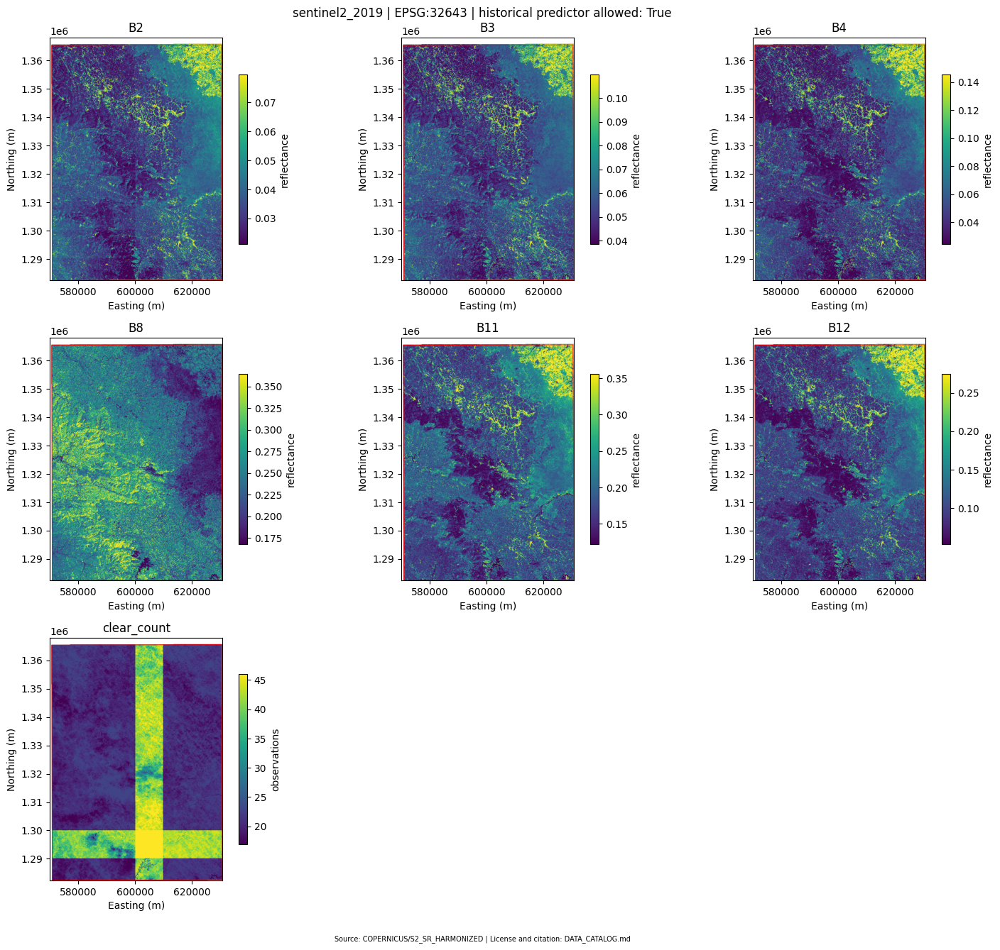

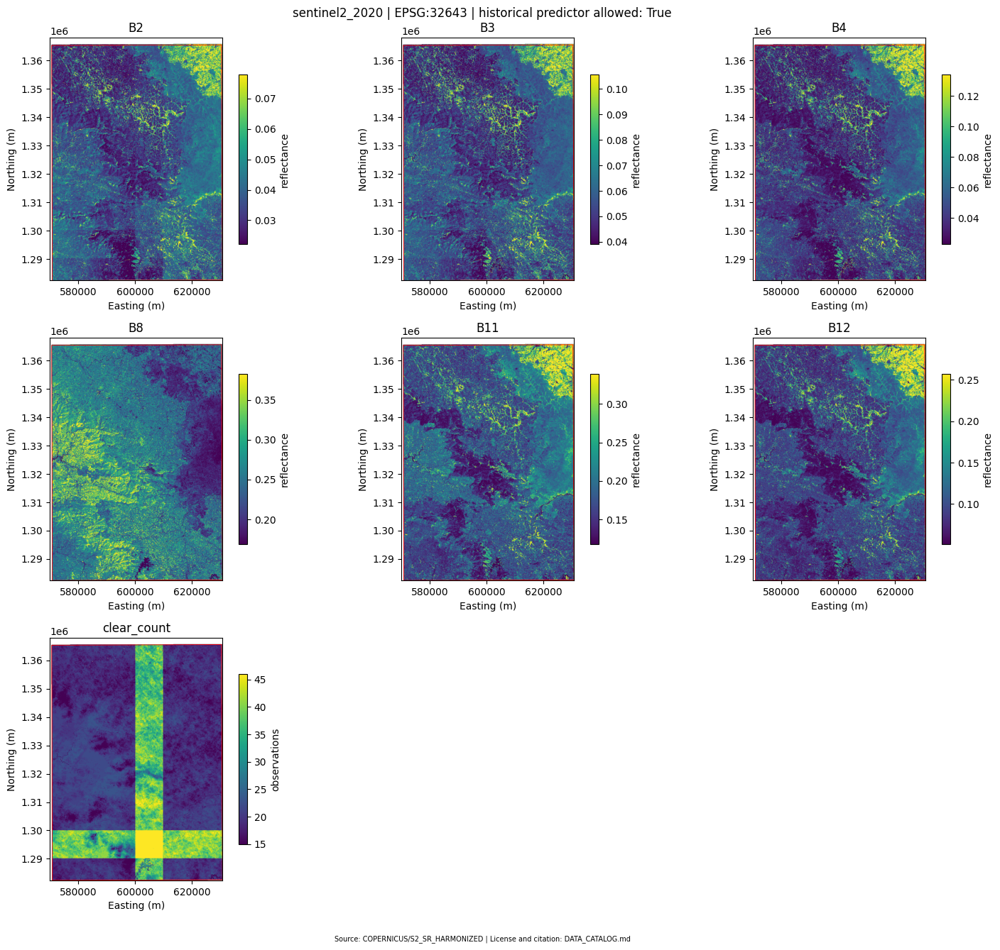

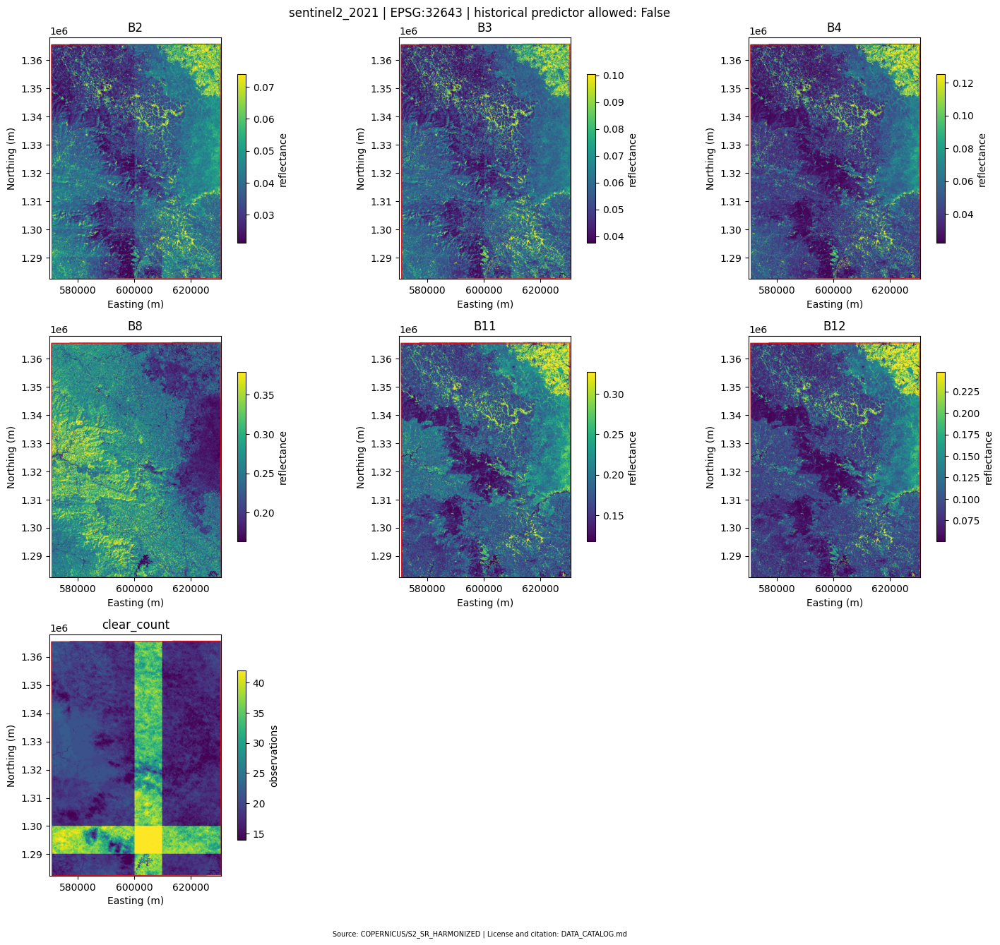

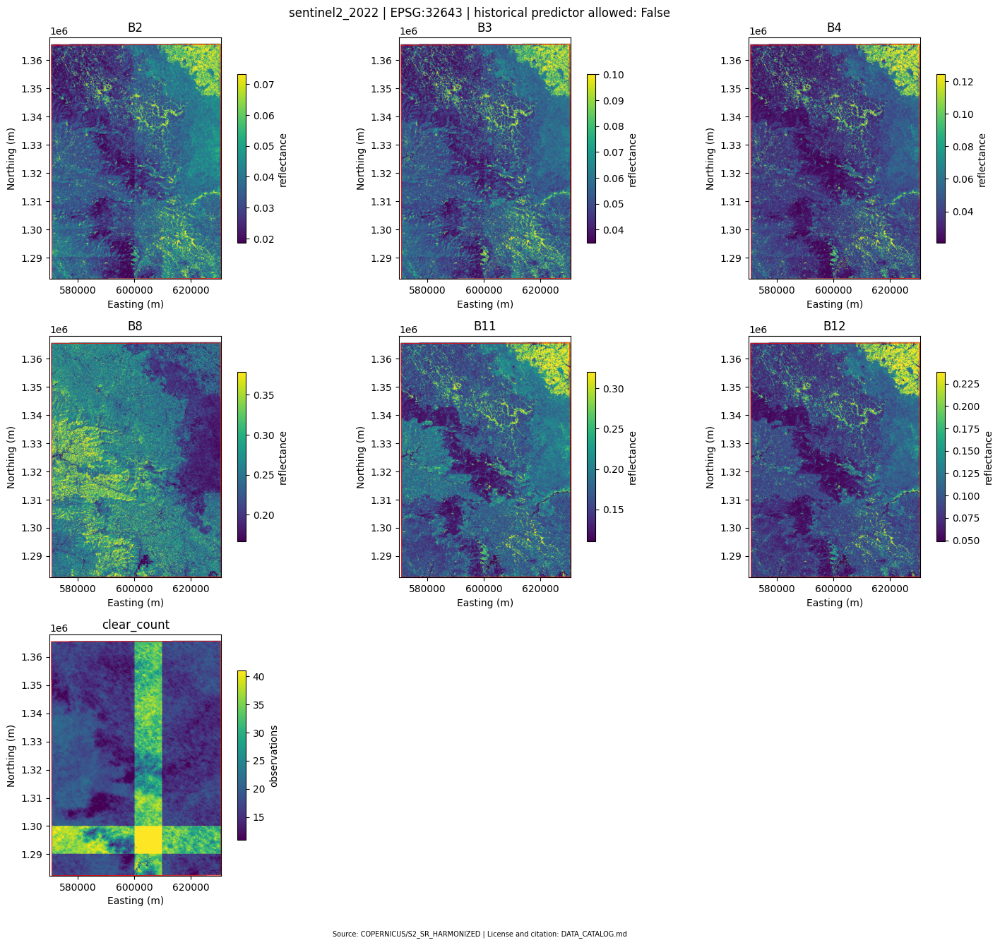

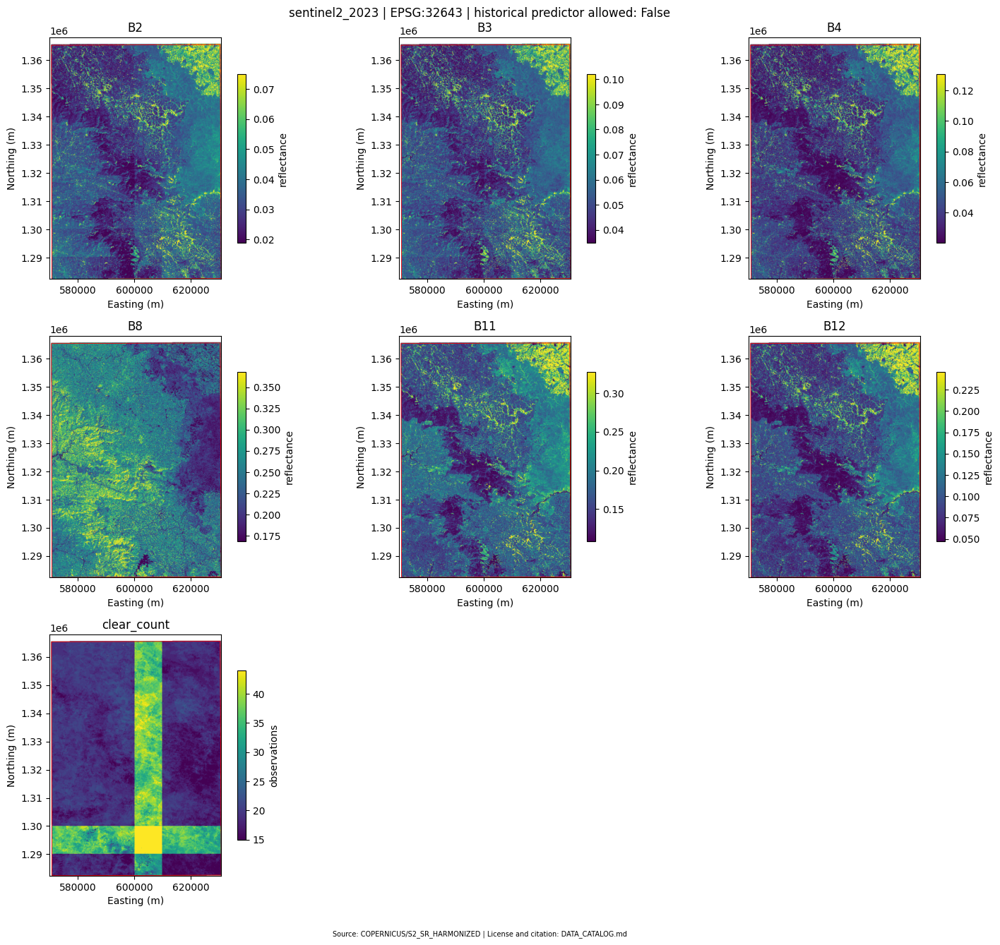

...

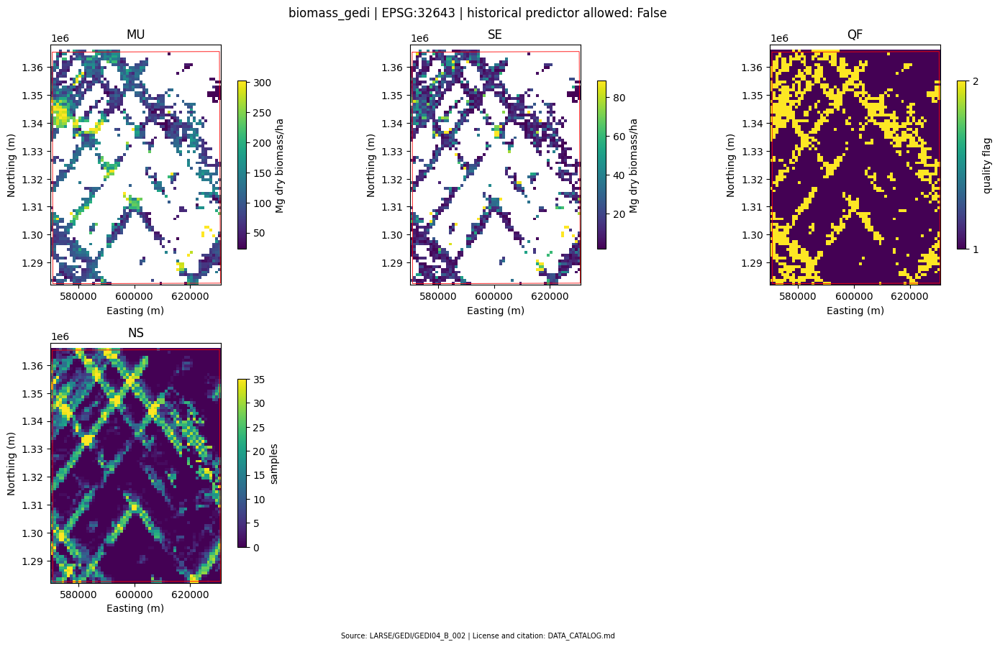

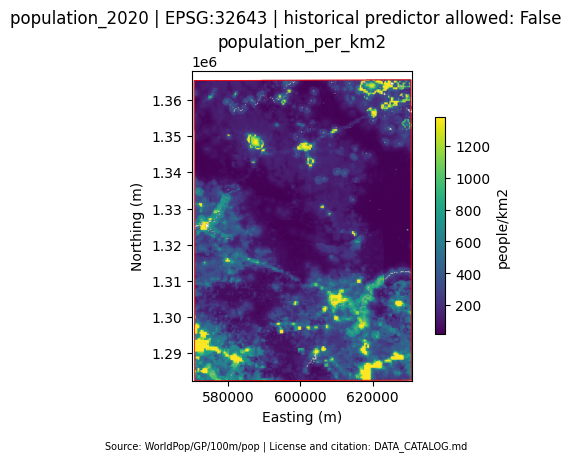

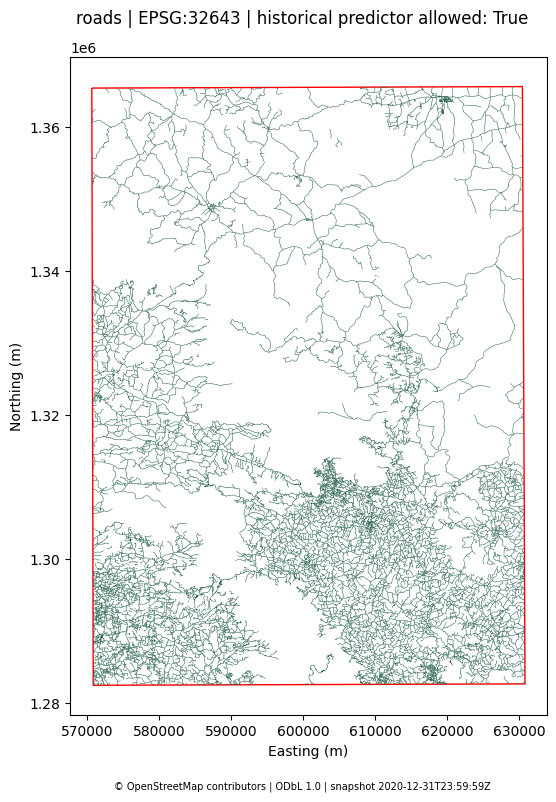

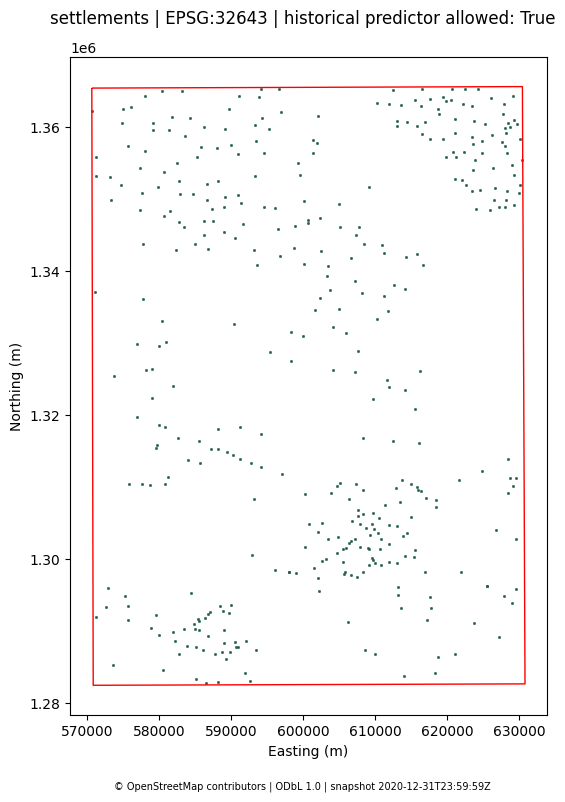

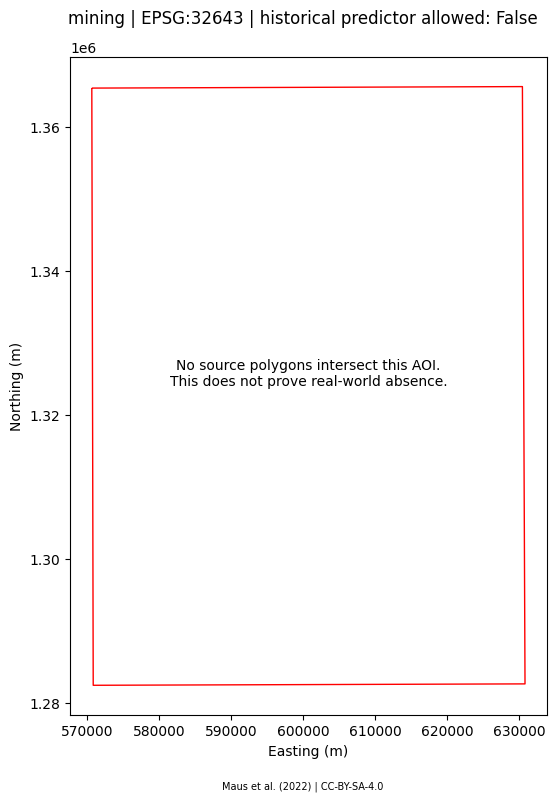

In [4]:
import matplotlib.pyplot as plt
from IPython.display import display
from src.data.plot_collection import figures
output = root / "reports" / "collection_sanity"
output.mkdir(parents=True, exist_ok=True)
for name, fig in figures(cfg):
    fig.savefig(output / f"{name}.png", dpi=120, bbox_inches="tight")
    display(fig)
    plt.close(fig)


## Human validation checklist

- Check AOI boundaries, cloud residuals, scene counts and missing pixels for all six optical years.
- Inspect loss/gain semantics, terrain units and north-crossing aspect values.
- Check precipitation totals, temperature plausibility and 0–7 cm soil moisture units.
- Inspect GEDI coverage, QF, sample counts and SE; its end date is after T=2020.
- Inspect OSM completeness and snapshot date; absence is not proof of no road/village.
- Confirm mining coverage with local evidence; do not infer legal status or causation.
- Review population covariate dates before historical feature admission.
- Preserve source attribution and licenses when distributing outputs.
